# 04 · Feature Selection
**UTS Data Science – Kelas RPL (DASI) · Daniel Haganta Ginting (41426090)**

| | |
|---|---|
| **Input** | `../data/processed/03_train_fe.csv` (scaled), `03_train_fe_unscaled.csv`, `03_test_fe.csv` |
| **Output** | `04_train_selected.csv`, `04_test_selected.csv`, `04_voting.csv`, `04_ringkasan.json`, grafik `../laporan/figures/04_*.png` |
| **Prinsip** | Semua seleksi dilakukan **hanya pada data latih** dengan validasi silang deret waktu (`TimeSeriesSplit`, 5 fold) supaya data uji tetap "belum pernah dilihat". |

Alur: (1) buang fitur konstan/quasi-konstan → (2) cek leakage → (3) tiga kelompok metode: Filter (Mutual Information),
Embedded (LassoCV, Random Forest), Wrapper (RFECV) → (4) voting → (5) bandingkan performa semua fitur vs fitur terpilih.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.feature_selection import mutual_info_regression, RFECV
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

PROC = Path("../data/processed")
FIG = Path("../laporan/figures")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})
from matplotlib.ticker import FuncFormatter
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # sumbu harga: 100000 -> 100.000
import textwrap

TARGET = "Harga_Cabai_Merah_Keriting"
META = ["Tanggal", "Kategori_Pasar"]
urut = lambda d: d.sort_values(["Tanggal", "Kategori_Pasar"]).reset_index(drop=True)   # urut waktu untuk TimeSeriesSplit
train = urut(pd.read_csv(PROC / "03_train_fe.csv", parse_dates=["Tanggal"]))
train_raw = urut(pd.read_csv(PROC / "03_train_fe_unscaled.csv", parse_dates=["Tanggal"]))
test = urut(pd.read_csv(PROC / "03_test_fe.csv", parse_dates=["Tanggal"]))
FITUR_AWAL = [c for c in train.columns if c not in META + [TARGET]]
y = train[TARGET]
tscv = TimeSeriesSplit(n_splits=5)
print("Train:", train.shape, "| Test:", test.shape, "| kolom fitur:", len(FITUR_AWAL),
      f"(= {len(FITUR_AWAL) - 2} fitur hasil feature engineering + 2 kolom asal: Harga_Cabai_Merah_Agregat, Is_Imputasi)")
R = {"fitur_awal": len(FITUR_AWAL)}

Train: (5144, 40) | Test: (1128, 40) | kolom fitur: 37 (= 35 fitur hasil feature engineering + 2 kolom asal: Harga_Cabai_Merah_Agregat, Is_Imputasi)


## 1 · Fitur konstan & quasi-konstan (> 95% nilai sama)

In [2]:
kons = pd.DataFrame({
    "nilai_terbanyak": [train_raw[c].mode().iloc[0] for c in FITUR_AWAL],
    "proporsi_nilai_terbanyak (%)": [train_raw[c].value_counts(normalize=True).iloc[0] * 100 for c in FITUR_AWAL],
    "jumlah_nilai_unik": [train_raw[c].nunique() for c in FITUR_AWAL],
    "varians (scaled)": [train[c].var() for c in FITUR_AWAL],
}, index=FITUR_AWAL).round(3).sort_values("proporsi_nilai_terbanyak (%)", ascending=False)
display(kons.head(8))
quasi = kons.index[kons["proporsi_nilai_terbanyak (%)"] > 95].tolist()
konstan = kons.index[kons["jumlah_nilai_unik"] <= 1].tolist()
print("Fitur konstan:", konstan)
print("Fitur quasi-konstan (> 95%):", quasi)
R["konstan"] = konstan; R["quasi_konstan"] = {c: float(kons.loc[c, "proporsi_nilai_terbanyak (%)"]) for c in quasi}

,nilai_terbanyak,proporsi_nilai_terbanyak (%),jumlah_nilai_unik,varians (scaled)
Is_Imputasi,0.0,98.425,2,0.016
Is_Ramadan,0.0,91.680,2,0.076
Is_Menjelang_Hari_Besar,0.0,89.813,2,0.092
Pasar_Pasar_Modern,0.0,75.000,2,0.188
Pasar_Pasar_Tradisional,0.0,75.000,2,0.188
Pasar_Pedagang_Besar,0.0,75.000,2,0.188
Kategori_Hujan_Lag1,1.0,73.328,4,1.000
Interaksi_Lag1_x_MusimHujan,0.0,66.096,267,1.000


Fitur konstan: []
Fitur quasi-konstan (> 95%): ['Is_Imputasi']


**Apa:** proporsi nilai terbanyak dihitung untuk tiap fitur pada data latih. Fitur dengan **lebih dari 95% nilai yang sama**
dibuang.

**Mengapa:** fitur yang hampir tidak pernah berubah hanya membawa sedikit informasi tetapi tetap menambah kompleksitas dan
noise. Beberapa model (misalnya Lasso) juga menjadi tidak stabil karenanya.

**Arti:**
- Tidak ada fitur yang benar-benar konstan.
- Hanya **`Is_Imputasi`** yang quasi-konstan: 98,4% bernilai 0, karena hanya sekitar 1,5% nilai yang diimputasi di NB01.
- `Is_Ramadan` (91,7%) dan `Is_Menjelang_Hari_Besar` (89,8%) masih di bawah ambang, jadi dipertahankan untuk diuji metode
  seleksi.

**Pengaruh:** `Is_Imputasi` dibuang dari kandidat model. Kolom ini tetap berguna sebagai penanda kualitas data di laporan.

## 2 · Pemeriksaan data leakage

In [3]:
kor_target = train_raw[FITUR_AWAL].corrwith(train_raw[TARGET], method="pearson").abs().sort_values(ascending=False)
WAKTU = {  # kapan nilai fitur diketahui relatif terhadap harga yang diprediksi (hari t)
    "Harga_Cabai_Merah_Agregat": "hari t (SAMA dengan target, dicatat bersamaan)",
    "Harga_Lag1": "t-1", "Harga_MA7": "t-7..t-1", "Interaksi_Lag1_x_MusimHujan": "t-1", "Harga_Lag5": "t-5",
    "Harga_MA20": "t-20..t-1", "Harga_Lag20": "t-20", "TE_Pasar_Bulan": "rata-rata train out-of-fold",
}
lk = pd.DataFrame({"|r| dgn target": kor_target.head(8).round(4)})
lk["waktu informasi"] = [WAKTU.get(c, "-") for c in lk.index]
lk["identik dgn target (%)"] = [round((train_raw[c] == train_raw[TARGET]).mean() * 100, 1) for c in lk.index]
lk["keputusan"] = np.where(lk.index == "Harga_Cabai_Merah_Agregat", "DROP - leakage", "aman (informasi masa lalu)")
display(lk)
d = train_raw[train_raw["Harga_Cabai_Merah_Agregat"] != train_raw[TARGET]]
print(f"Agregat berbeda dari target hanya di {len(d)} dari {len(train_raw)} baris train; per pasar:",
      d["Kategori_Pasar"].value_counts().to_dict())
per_pasar = train_raw.groupby("Kategori_Pasar").apply(lambda g: pd.Series({
    "identik dgn target (%)": (g["Harga_Cabai_Merah_Agregat"] == g[TARGET]).mean() * 100,
    "pearson r": g["Harga_Cabai_Merah_Agregat"].corr(g[TARGET])})).round(4)
print("Agregat vs target per pasar (data latih):")
display(per_pasar)

# Uji praktis: seberapa 'terlalu sempurna' model jika Agregat dipakai?
def cv_lr(cols):
    s = cross_validate(LinearRegression(), train[cols], y, cv=tscv, scoring=("neg_mean_absolute_error", "r2"))
    return -s["test_neg_mean_absolute_error"].mean(), s["test_r2"].mean()
mae_ag, r2_ag = cv_lr(["Harga_Cabai_Merah_Agregat"])
mae_l1, r2_l1 = cv_lr(["Harga_Lag1"])
print(f"LinearRegression 1 fitur Agregat: MAE Rp{mae_ag:,.0f}, R2 {r2_ag:.4f}  vs  1 fitur Harga_Lag1: MAE Rp{mae_l1:,.0f}, R2 {r2_l1:.4f}")
LEAKAGE = ["Harga_Cabai_Merah_Agregat"]
R["leakage"] = {"fitur": LEAKAGE, "r_agregat": float(kor_target["Harga_Cabai_Merah_Agregat"]),
                "identik_pct": float(lk.loc["Harga_Cabai_Merah_Agregat", "identik dgn target (%)"]),
                "mae_agregat": round(mae_ag), "r2_agregat": round(r2_ag, 4), "mae_lag1": round(mae_l1), "r2_lag1": round(r2_l1, 4),
                "r_lag1": float(kor_target["Harga_Lag1"]), "per_pasar": per_pasar.to_dict(orient="index")}

,|r| dgn target,waktu informasi,identik dgn target (%),keputusan
Harga_Lag1,0.9782,t-1,77.7,aman (informasi masa lalu)
Harga_MA7,0.9435,t-7..t-1,26.4,aman (informasi masa lalu)
Harga_Cabai_Merah_Agregat,0.9155,"hari t (SAMA dengan target, dicatat bersamaan)",95.1,DROP - leakage
Harga_Lag5,0.8995,t-5,33.0,aman (informasi masa lalu)
Harga_MA20,0.8829,t-20..t-1,2.7,aman (informasi masa lalu)
Harga_PB_Lag1,0.7447,-,21.1,aman (informasi masa lalu)
Harga_Lag20,0.7022,t-20,3.8,aman (informasi masa lalu)
Harga_Produsen_Lag1,0.6726,-,24.3,aman (informasi masa lalu)


Agregat berbeda dari target hanya di 252 dari 5144 baris train; per pasar: {'Pasar Modern': 241, 'Pedagang Besar': 10, 'Pasar Tradisional': 1}
Agregat vs target per pasar (data latih):


,identik dgn target (%),pearson r
Kategori_Pasar,,
Pasar Modern,81.2597,0.7207
Pasar Tradisional,99.9222,0.9998
Pedagang Besar,99.2224,1.0000
Produsen,100.0000,1.0000


LinearRegression 1 fitur Agregat: MAE Rp2,156, R2 0.6364  vs  1 fitur Harga_Lag1: MAE Rp1,410, R2 0.9484


**Apa:** pemeriksaan leakage dengan dua cara: (1) korelasi yang terlalu sempurna dengan target, dan (2) logika waktu, yaitu
apakah nilai fitur sudah diketahui **sebelum** harga hari t terjadi.

**Arti:**
- `Harga_Cabai_Merah_Agregat` dicatat **pada hari yang sama** dengan target. Nilainya **identik dengan target di 95,1%
  baris**: Produsen 100%, Pedagang Besar 99,2%, Pasar Tradisional 99,9%, dengan korelasi r = 1,000 / 1,000 / 0,9998.
  Hanya Pasar Modern yang berbeda (81,3%, r = 0,72), dan perbedaan ini yang membuat korelasi gabungannya "hanya" 0,92.
  Kolom ini pada dasarnya adalah target itu sendiri. Di hari nyata, nilainya tidak tersedia sebelum harga yang ingin
  diprediksi diketahui. → **DROP (leakage).**
- `Harga_Lag1` juga berkorelasi sangat tinggi (r = 0,978), tetapi diambil dari **hari kerja sebelumnya (t-1)**, sehingga
  tersedia saat prediksi dibuat. Ini bukan leakage, melainkan sifat harga yang lengket (autokorelasi 0,96 di EDA). Hal yang
  sama berlaku untuk Lag5/Lag20/MA. Semuanya digeser `shift(1)` per pasar di NB03.
- `TE_Pasar_Bulan` aman karena dihitung out-of-fold dan hanya dari data latih.

**Pengaruh:** kandidat menjadi 35 fitur (37 kolom fitur − Agregat − Is_Imputasi), yaitu tepat **35 fitur hasil feature
engineering** dari Tahap 3. Dampak leakage juga terlihat di tabel perbandingan
bagian 5: memasukkan Agregat menurunkan CV MAE secara semu.

In [4]:
DIBUANG_AWAL = sorted(set(konstan + quasi + LEAKAGE))
KANDIDAT = [c for c in FITUR_AWAL if c not in DIBUANG_AWAL]
X = train[KANDIDAT]
print(f"Dibuang sebelum seleksi: {DIBUANG_AWAL} -> kandidat tersisa {len(KANDIDAT)} fitur")
R["kandidat"] = len(KANDIDAT); R["dibuang_awal"] = DIBUANG_AWAL

Dibuang sebelum seleksi: ['Harga_Cabai_Merah_Agregat', 'Is_Imputasi'] -> kandidat tersisa 35 fitur


## 3 · Metode seleksi (3 kelompok)

In [5]:
# FILTER - Mutual Information (menangkap hubungan non-linear, tidak bergantung model)
mi = pd.Series(mutual_info_regression(X, y, random_state=RANDOM_STATE), index=KANDIDAT).sort_values(ascending=False)
K = 15
pilih_mi = mi.head(K).index.tolist()

# EMBEDDED 1 - LassoCV (regularisasi L1 mengecilkan koefisien fitur tak berguna menjadi 0)
lasso = LassoCV(cv=tscv, random_state=RANDOM_STATE, max_iter=50000, n_alphas=100).fit(X, y)
coef = pd.Series(lasso.coef_, index=KANDIDAT)
pilih_lasso = coef.index[coef.abs() > 1e-6].tolist()

# EMBEDDED 2 - Random Forest (impurity importance)
rf = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=KANDIDAT).sort_values(ascending=False)
pilih_rf = imp.head(K).index.tolist()

# WRAPPER - RFECV dengan LinearRegression (mencari jumlah fitur optimal via CV deret waktu)
rfecv = RFECV(LinearRegression(), step=1, cv=tscv, scoring="neg_mean_absolute_error", min_features_to_select=3).fit(X, y)
pilih_rfe = [c for c, s in zip(KANDIDAT, rfecv.support_) if s]

print(f"MI (top {K}):", pilih_mi)
print(f"Lasso (alpha={lasso.alpha_:.2f}, koef != 0: {len(pilih_lasso)}):", pilih_lasso)
print(f"Random Forest (top {K}):", pilih_rf)
print(f"RFECV (optimal {rfecv.n_features_} fitur):", pilih_rfe)
R["lasso_alpha"] = round(float(lasso.alpha_), 2); R["n_lasso"] = len(pilih_lasso); R["n_rfecv"] = int(rfecv.n_features_)

MI (top 15): ['Harga_Lag1', 'Harga_Lag5', 'Harga_Lag20', 'Harga_Produsen_Lag1', 'Rasio_Thd_Grosir_Lag1', 'Momentum_5H', 'Harga_PB_Lag1', 'Harga_MA7', 'TE_Pasar_Bulan', 'Interaksi_Lag1_x_MusimHujan', 'Harga_MA20', 'Bulan', 'Level_Rantai_Pasok', 'Hari_Menuju_Idul_Fitri', 'Bulan_cos']
Lasso (alpha=130.18, koef != 0: 9): ['Harga_Lag1', 'Harga_MA7', 'Harga_MA20', 'Harga_PB_Lag1', 'Akumulasi_Hujan_7H', 'Level_Rantai_Pasok', 'Interaksi_Lag1_x_MusimHujan', 'TE_Pasar_Bulan', 'Kategori_Suhu_Lag1']
Random Forest (top 15): ['Harga_Lag1', 'Hari_Menuju_Idul_Fitri', 'Harga_Lag5', 'Akumulasi_Hujan_7H', 'Hujan_Lag1', 'TE_Pasar_Bulan', 'Harga_MA7', 'Harga_Lag20', 'Akumulasi_Hujan_60H_Lag11Mgg', 'Angin_Lag1', 'Akumulasi_Hujan_30H', 'Harga_Produsen_Lag1', 'Harga_MA20', 'Suhu_Lag1', 'Harga_Std7']
RFECV (optimal 3 fitur): ['Harga_Lag1', 'Harga_Lag5', 'Harga_MA7']


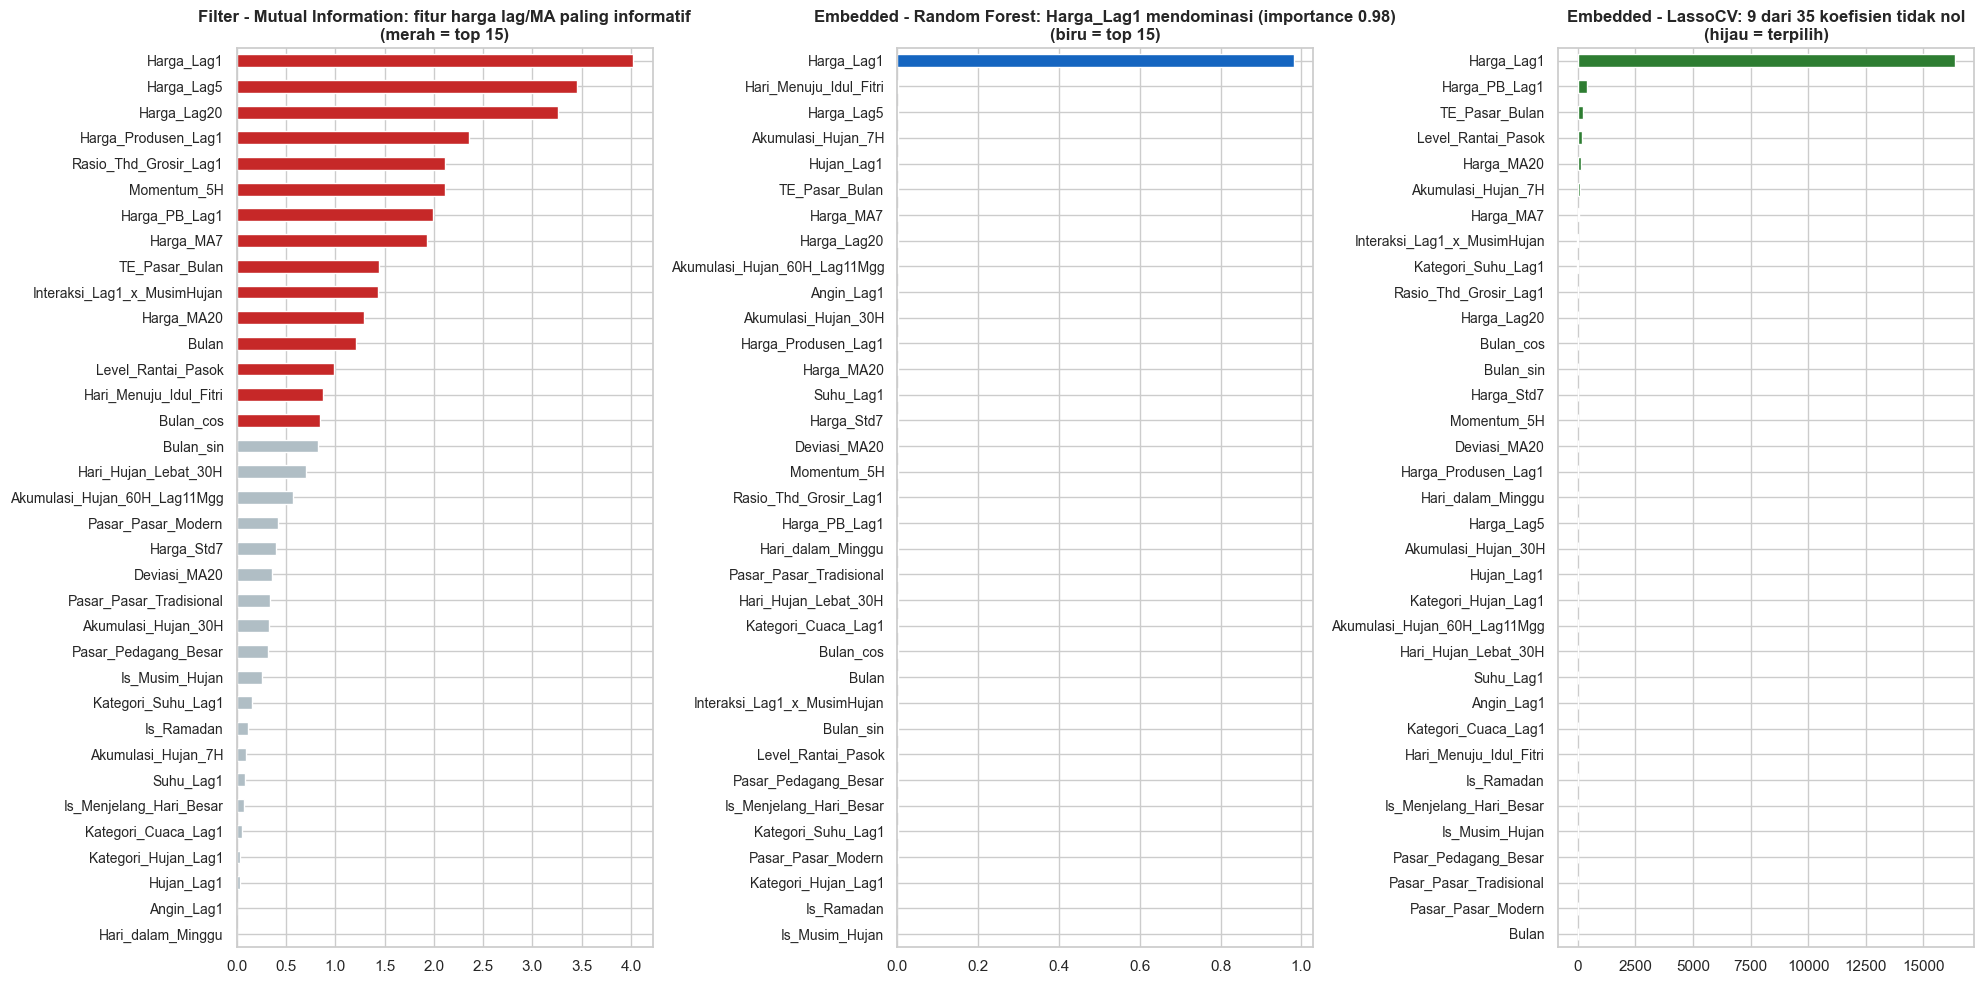

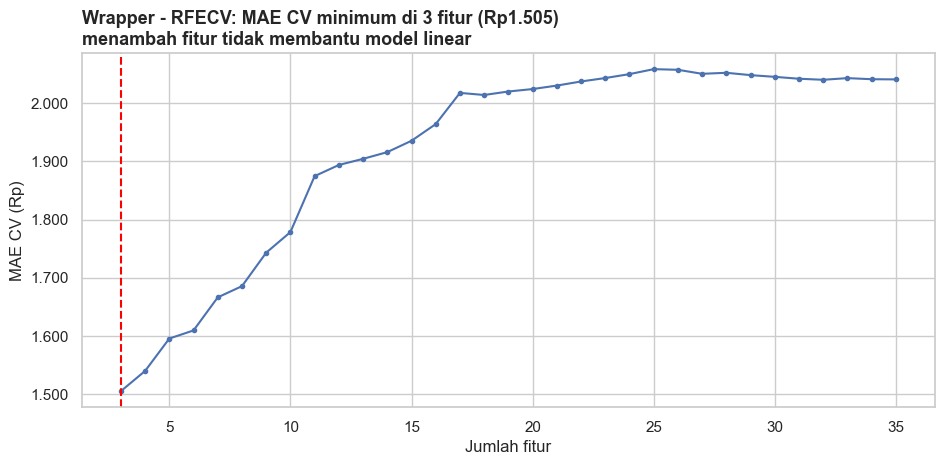

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
mi.sort_values().plot.barh(ax=axes[0], color=["#c62828" if c in pilih_mi else "#b0bec5" for c in mi.sort_values().index])
axes[0].set_title(f"Filter - Mutual Information: fitur harga lag/MA paling informatif\n(merah = top {K})", fontsize=12)
imp.sort_values().plot.barh(ax=axes[1], color=["#1565c0" if c in pilih_rf else "#b0bec5" for c in imp.sort_values().index])
axes[1].set_title(f"Embedded - Random Forest: Harga_Lag1 mendominasi (importance {imp.iloc[0]:.2f})\n(biru = top {K})", fontsize=12)
coef.reindex(coef.abs().sort_values().index).plot.barh(ax=axes[2], color=["#2e7d32" if abs(v) > 1e-6 else "#b0bec5" for v in coef.reindex(coef.abs().sort_values().index)])
axes[2].set_title(f"Embedded - LassoCV: {len(pilih_lasso)} dari {len(KANDIDAT)} koefisien tidak nol\n(hijau = terpilih)", fontsize=12)
for a in axes: a.tick_params(axis="y", labelsize=10)
plt.tight_layout(); plt.savefig(FIG / "04_skor_metode_seleksi.png"); plt.show()

sc = -rfecv.cv_results_["mean_test_score"]
n_feat = np.arange(rfecv.min_features_to_select, rfecv.min_features_to_select + len(sc))
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(n_feat, sc, marker="o", ms=3); ax.axvline(rfecv.n_features_, color="red", ls="--")
ax.set_title(f"Wrapper - RFECV: MAE CV minimum di {rfecv.n_features_} fitur (Rp{sc.min():,.0f})\nmenambah fitur tidak membantu model linear".replace(",", "."), loc="left")
ax.set_xlabel("Jumlah fitur"); ax.set_ylabel("MAE CV (Rp)"); ax.yaxis.set_major_formatter(RIBUAN)
plt.savefig(FIG / "04_rfecv_kurva.png"); plt.show()
R["rfecv_mae_min"] = round(float(sc.min()))

**Apa:** empat metode dari tiga kelompok berbeda, semuanya di-fit pada data latih dengan `TimeSeriesSplit(5)` bila perlu CV.

| Metode | Kelompok | Cara memilih | Jumlah terpilih |
|---|---|---|---|
| Mutual Information | Filter | 15 skor MI tertinggi (menangkap hubungan non-linear) | 15 |
| LassoCV | Embedded | koefisien ≠ 0 pada alpha optimal 130,18 | 9 |
| Random Forest (300 pohon) | Embedded | 15 importance tertinggi | 15 |
| RFECV + LinearRegression | Wrapper | jumlah fitur dengan MAE CV terkecil | 3 |

**Mengapa beberapa metode:** setiap metode punya bias.
- MI tidak melihat redundansi antarfitur.
- Lasso cenderung memilih satu wakil dari fitur yang saling berkorelasi.
- RF menyukai fitur kontinu dengan banyak nilai unik, misalnya fitur hujan harian.
- RFECV bergantung pada model linear.

Voting menggabungkan keempatnya agar keputusan tidak bergantung pada satu metode saja.

**Arti:**
- Keempat metode sepakat bahwa **`Harga_Lag1`** paling penting (RF importance 0,98).
- RFECV menunjukkan bahwa untuk regresi linear, 3 fitur (Lag1, Lag5, MA7) sudah mencapai MAE CV minimum (Rp1.505). Menambah
  fitur lain justru tidak membantu.
- RF memilih beberapa fitur cuaca harian (Hujan_Lag1, Angin_Lag1), tetapi importance-nya sangat kecil (< 0,002).

## 4 · Voting antar-metode

,MI (filter),Lasso (embedded),Random Forest (embedded),RFECV (wrapper),total_suara,MI_skor,RF_importance,Lasso_koef,keputusan
Harga_Lag1,1,1,1,1,4,4.019,0.9807,16374.3,PILIH
Harga_MA7,1,1,1,1,4,1.934,0.0011,43.7,PILIH
Harga_Lag5,1,0,1,1,3,3.449,0.0015,0.0,PILIH
TE_Pasar_Bulan,1,1,1,0,3,1.438,0.0012,248.7,PILIH
Harga_MA20,1,1,1,0,3,1.288,0.0007,127.9,PILIH
Harga_Lag20,1,0,1,0,2,3.257,0.0011,0.0,PILIH
Harga_Produsen_Lag1,1,0,1,0,2,2.358,0.0008,0.0,PILIH
Harga_PB_Lag1,1,1,0,0,2,1.996,0.0005,422.2,PILIH
Interaksi_Lag1_x_MusimHujan,1,1,0,0,2,1.432,0.0002,-25.9,PILIH
Level_Rantai_Pasok,1,1,0,0,2,0.983,0.0001,175.6,PILIH


Fitur final (>= 2 suara dari 4): 12 -> ['Harga_Lag1', 'Harga_MA7', 'Harga_Lag5', 'TE_Pasar_Bulan', 'Harga_MA20', 'Harga_Lag20', 'Harga_Produsen_Lag1', 'Harga_PB_Lag1', 'Interaksi_Lag1_x_MusimHujan', 'Level_Rantai_Pasok', 'Hari_Menuju_Idul_Fitri', 'Akumulasi_Hujan_7H']


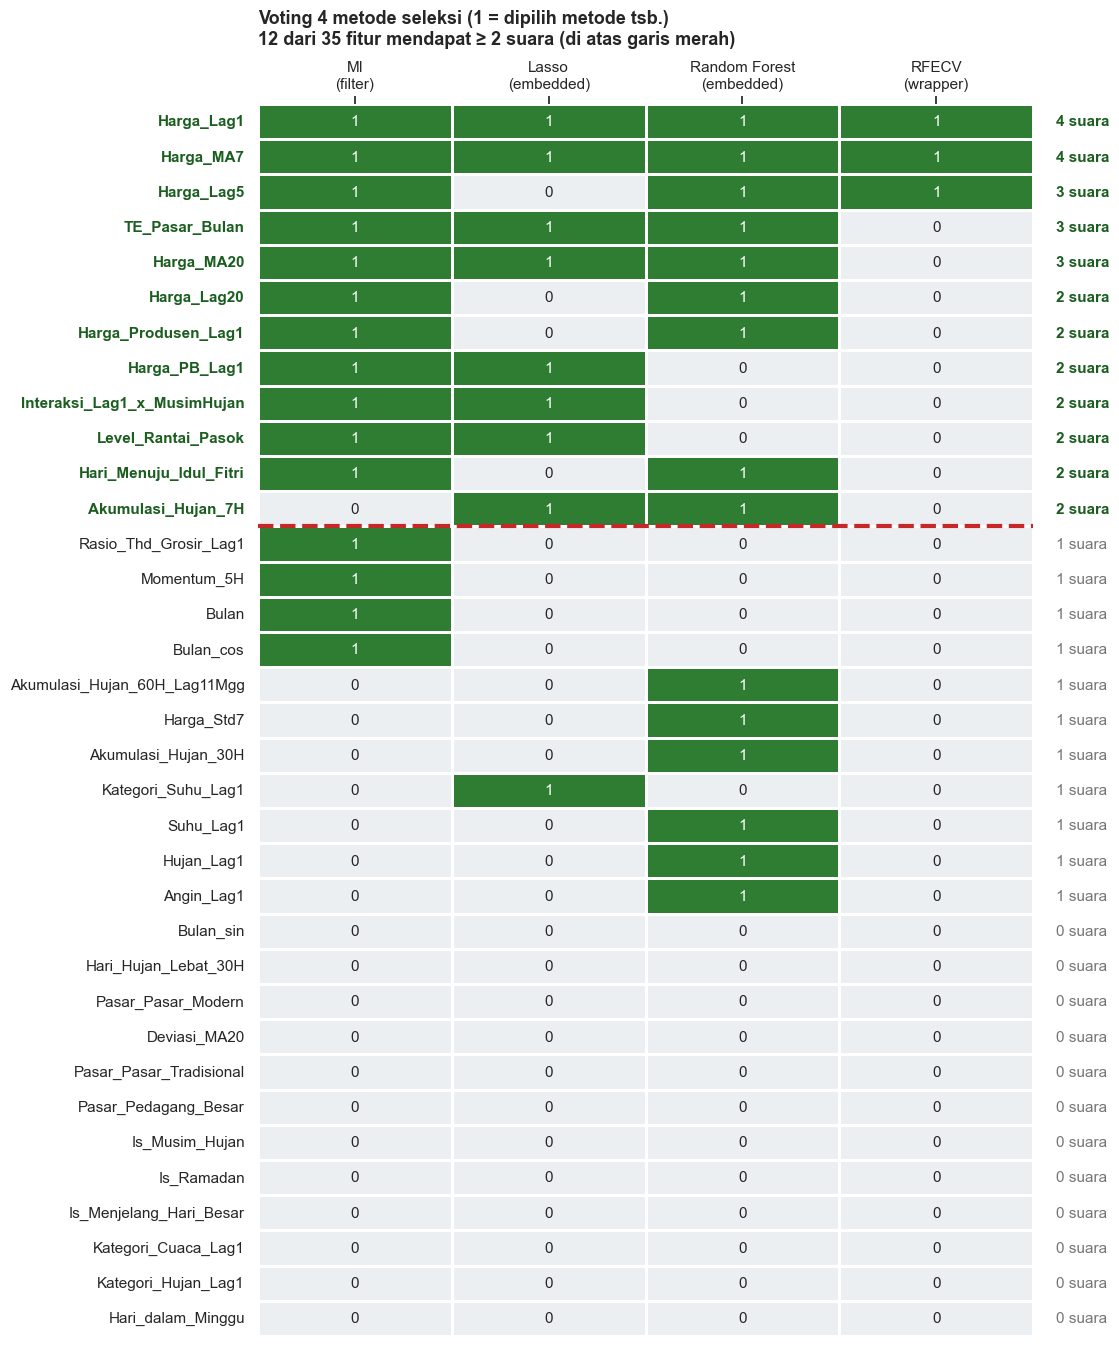

In [7]:
vote = pd.DataFrame({"MI (filter)": [c in pilih_mi for c in KANDIDAT], "Lasso (embedded)": [c in pilih_lasso for c in KANDIDAT],
                     "Random Forest (embedded)": [c in pilih_rf for c in KANDIDAT], "RFECV (wrapper)": [c in pilih_rfe for c in KANDIDAT]},
                    index=KANDIDAT).astype(int)
vote["total_suara"] = vote.sum(axis=1)
vote["MI_skor"] = mi.reindex(KANDIDAT).round(3); vote["RF_importance"] = imp.reindex(KANDIDAT).round(4); vote["Lasso_koef"] = coef.round(1)
vote = vote.sort_values(["total_suara", "MI_skor"], ascending=False)
MIN_SUARA = 2
vote["keputusan"] = np.where(vote["total_suara"] >= MIN_SUARA, "PILIH", "buang")
FINAL = vote.index[vote["keputusan"] == "PILIH"].tolist()
display(vote)
vote.to_csv(PROC / "04_voting.csv", index_label="fitur")
print(f"Fitur final (>= {MIN_SUARA} suara dari 4): {len(FINAL)} ->", FINAL)

METODE = ["MI (filter)", "Lasso (embedded)", "Random Forest (embedded)", "RFECV (wrapper)"]
fig, ax = plt.subplots(figsize=(10, 0.4 * len(vote) + 2))
sns.heatmap(vote[METODE], cmap=["#eceff1", "#2e7d32"], cbar=False, linewidths=1, linecolor="white",
            annot=True, fmt="d", annot_kws={"fontsize": 11}, ax=ax)
ax.xaxis.tick_top()
ax.set_xticklabels(["MI\n(filter)", "Lasso\n(embedded)", "Random Forest\n(embedded)", "RFECV\n(wrapper)"], rotation=0, fontsize=11)
for i, t in enumerate(vote["total_suara"]):
    ax.text(4.12, i + 0.5, f"{t} suara", va="center", fontsize=11, fontweight="bold" if t >= MIN_SUARA else "normal",
            color="#1b5e20" if t >= MIN_SUARA else "#757575")
ax.axhline(len(FINAL), color="#c62828", lw=3, ls="--", clip_on=False)
for lbl in ax.get_yticklabels():
    if lbl.get_text() in FINAL:
        lbl.set_fontweight("bold"); lbl.set_color("#1b5e20")
ax.tick_params(axis="y", labelsize=11); ax.set_ylabel("")
ax.set_title(f"Voting 4 metode seleksi (1 = dipilih metode tsb.)\n{len(FINAL)} dari {len(KANDIDAT)} fitur mendapat ≥ {MIN_SUARA} suara (di atas garis merah)",
             loc="left", pad=12)
plt.savefig(FIG / "04_voting_heatmap.png"); plt.show()
R["final"] = FINAL; R["n_final"] = len(FINAL); R["suara"] = vote["total_suara"].to_dict()

**Apa:** tabel voting. Fitur dipilih jika mendapat **≥ 2 suara dari 4 metode**.

**Mengapa ambang 2:** satu suara bisa muncul karena bias satu metode, misalnya RF yang memilih fitur cuaca acak. Ambang 3–4
terlalu ketat karena RFECV hanya memilih 3 fitur. Dengan ambang 2, sebuah fitur harus "disetujui" oleh minimal dua sudut
pandang yang berbeda.

**Arti:** terpilih **12 dari 35 fitur**:
- **Harga sendiri:** Lag1, Lag5, Lag20, MA7, MA20.
- **Rantai pasok:** Harga_PB_Lag1, Harga_Produsen_Lag1, Level_Rantai_Pasok.
- **Musiman:** TE_Pasar_Bulan, Interaksi_Lag1_x_MusimHujan.
- **Kalender:** Hari_Menuju_Idul_Fitri.
- **Cuaca:** Akumulasi_Hujan_7H.

Fitur yang dibuang antara lain flag Is_Musim_Hujan / Is_Ramadan / Is_Menjelang_Hari_Besar (0 suara), one-hot pasar
(informasinya sudah diwakili `Level_Rantai_Pasok` dan `TE_Pasar_Bulan`), dan `Akumulasi_Hujan_60H_Lag11Mgg` (1 suara, RF).

**Pengaruh:** 12 fitur ini diteruskan ke Tahap 5 untuk dicek multikolinearitasnya.

## 5 · Perbandingan performa: semua fitur vs fitur terpilih

,skenario,jumlah_fitur,CV MAE (Rp),CV RMSE (Rp),CV R2,CV MAPE (%),Test MAE (Rp),Test R2,Test MAPE (%)
0,Baseline naif (harga kemarin),1,1244.0,3891.0,0.9479,3.28,1612.0,0.9455,3.65
1,Semua fitur (termasuk leakage),37,1314.0,3571.0,0.8662,2.82,2109.0,0.9596,5.11
2,Semua fitur tanpa leakage & quasi-konstan,35,2041.0,4071.0,0.9444,5.74,2339.0,0.9443,5.51
3,Fitur terpilih (voting >= 2),12,1694.0,3864.0,0.9490,4.64,2207.0,0.9458,5.21


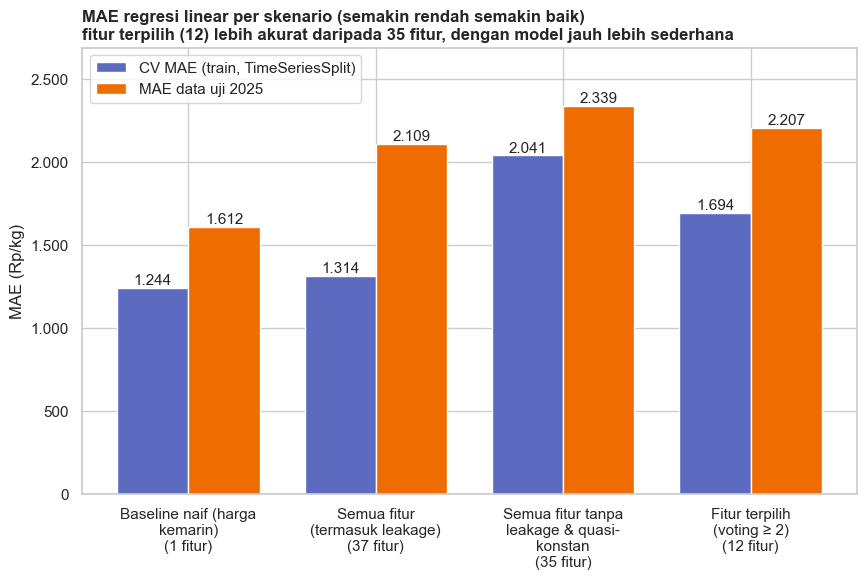

In [8]:
def evaluasi(cols, nama):
    s = cross_validate(LinearRegression(), train[cols], y, cv=tscv,
                       scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2", "neg_mean_absolute_percentage_error"))
    m = LinearRegression().fit(train[cols], y); p = m.predict(test[cols])
    return {"skenario": nama, "jumlah_fitur": len(cols),
            "CV MAE (Rp)": -s["test_neg_mean_absolute_error"].mean(), "CV RMSE (Rp)": -s["test_neg_root_mean_squared_error"].mean(),
            "CV R2": s["test_r2"].mean(), "CV MAPE (%)": -s["test_neg_mean_absolute_percentage_error"].mean() * 100,
            "Test MAE (Rp)": mean_absolute_error(test[TARGET], p), "Test R2": r2_score(test[TARGET], p),
            "Test MAPE (%)": mean_absolute_percentage_error(test[TARGET], p) * 100}

# baseline naif: prediksi = harga kemarin (tanpa model); Harga_Lag1 test dikembalikan ke Rupiah memakai mean/std train
mu, sd = train_raw["Harga_Lag1"].mean(), train_raw["Harga_Lag1"].std(ddof=0)
lag1_test_rp = test["Harga_Lag1"] * sd + mu
naif_cv = [mean_absolute_error(y.iloc[te], train_raw["Harga_Lag1"].iloc[te]) for _, te in tscv.split(train)]
hasil = pd.DataFrame([
    {"skenario": "Baseline naif (harga kemarin)", "jumlah_fitur": 1, "CV MAE (Rp)": np.mean(naif_cv),
     "CV RMSE (Rp)": np.mean([mean_squared_error(y.iloc[te], train_raw["Harga_Lag1"].iloc[te]) ** .5 for _, te in tscv.split(train)]),
     "CV R2": np.mean([r2_score(y.iloc[te], train_raw["Harga_Lag1"].iloc[te]) for _, te in tscv.split(train)]),
     "CV MAPE (%)": np.mean([mean_absolute_percentage_error(y.iloc[te], train_raw["Harga_Lag1"].iloc[te]) for _, te in tscv.split(train)]) * 100,
     "Test MAE (Rp)": mean_absolute_error(test[TARGET], lag1_test_rp), "Test R2": r2_score(test[TARGET], lag1_test_rp),
     "Test MAPE (%)": mean_absolute_percentage_error(test[TARGET], lag1_test_rp) * 100},
    evaluasi(FITUR_AWAL, "Semua fitur (termasuk leakage)"),
    evaluasi(KANDIDAT, "Semua fitur tanpa leakage & quasi-konstan"),
    evaluasi(FINAL, "Fitur terpilih (voting >= 2)"),
])
hasil_tampil = hasil.copy()
for c in hasil_tampil.columns[2:]:
    hasil_tampil[c] = hasil_tampil[c].round(4 if "R2" in c else (2 if "MAPE" in c else 0))
display(hasil_tampil)
R["perbandingan"] = hasil_tampil.to_dict(orient="records")

fig, ax = plt.subplots(figsize=(10, 5.8))
h = hasil.set_index("skenario")
x = np.arange(len(h)); w = .38
ax.bar(x - w/2, h["CV MAE (Rp)"], w, label="CV MAE (train, TimeSeriesSplit)", color="#5c6bc0")
ax.bar(x + w/2, h["Test MAE (Rp)"], w, label="MAE data uji 2025", color="#ef6c00")
for i, (a, b) in enumerate(zip(h["CV MAE (Rp)"], h["Test MAE (Rp)"])):
    ax.text(i - w/2, a, f"{a:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=11)
    ax.text(i + w/2, b, f"{b:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=11)
ax.set_xticks(x, [textwrap.fill(s.replace(">=", "≥"), 20) + f"\n({n} fitur)" for s, n in zip(h.index, h["jumlah_fitur"])], fontsize=11)
ax.set_ylabel("MAE (Rp/kg)"); ax.legend(fontsize=11, loc="upper left"); ax.yaxis.set_major_formatter(RIBUAN); ax.set_ylim(0, h[["CV MAE (Rp)", "Test MAE (Rp)"]].max().max() * 1.15)
ax.set_title(f"MAE regresi linear per skenario (semakin rendah semakin baik)\nfitur terpilih ({len(FINAL)}) lebih akurat daripada {len(KANDIDAT)} fitur, dengan model jauh lebih sederhana", loc="left", fontsize=12)
plt.savefig(FIG / "04_perbandingan_performa.png"); plt.show()

**Apa:** perbandingan `LinearRegression` dengan CV deret waktu (5 fold, data latih) dan evaluasi pada data uji 2025, untuk
empat skenario. Baseline naif "harga besok = harga hari ini" ditambahkan sebagai pembanding jujur.

**Arti:**
- **Fitur terpilih (12) vs semua fitur bersih (35):** CV MAE turun dari **Rp2.041 menjadi Rp1.694 (−17%)**, RMSE dari
  Rp4.071 menjadi Rp3.864, dan R² naik dari 0,9444 menjadi 0,9490. Di data uji, MAE turun dari Rp2.339 menjadi Rp2.207.
  Jadi **dengan sepertiga jumlah fitur, model lebih akurat dan lebih sederhana**. Fitur yang dibuang memang hanya menambah
  noise.
- **Efek leakage:** dengan Agregat (37 fitur), CV MAE terlihat jauh lebih baik (Rp1.314). Ini kebaikan **semu** karena
  model "mencontek" harga hari yang sama.
- **Catatan jujur:** baseline naif masih memiliki MAE terkecil (CV Rp1.244; uji Rp1.612), karena harga cabai sangat lengket
  (berubah hanya di 57% hari untuk Pasar Tradisional). Model linear sedikit unggul di RMSE (Rp3.864 vs Rp3.891), artinya
  model lebih baik pada hari-hari dengan perubahan besar, tetapi kalah pada hari-hari tanpa perubahan.

**Pengaruh untuk UAS:** target sebaiknya diubah menjadi **perubahan harga** (Δ = harga t − harga t-1) atau log-return.
Gunakan model non-linear (Random Forest/XGBoost), dan **setiap model wajib dibandingkan dengan baseline naif**.

In [9]:
train[META + [TARGET] + FINAL].to_csv(PROC / "04_train_selected.csv", index=False)
test[META + [TARGET] + FINAL].to_csv(PROC / "04_test_selected.csv", index=False)
(PROC / "04_ringkasan.json").write_text(json.dumps(R, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Tersimpan. Fitur final:", len(FINAL))

Tersimpan. Fitur final: 12


## Ringkasan Tahap 4
| Tahap | Jumlah fitur |
|---|---|
| Kolom fitur di `03_train_fe.csv` (35 fitur hasil feature engineering + 2 kolom asal) | 37 |
| − quasi-konstan (`Is_Imputasi`) & leakage (`Harga_Cabai_Merah_Agregat`) = 35 fitur hasil feature engineering | 35 |
| Voting ≥ 2 dari 4 metode (MI, Lasso, RF, RFECV) | **12** |

Hasilnya: CV MAE regresi linear membaik dari Rp2.041 (35 fitur) menjadi **Rp1.694 (12 fitur)**. File
`04_train_selected.csv` dan `04_test_selected.csv` menjadi input Tahap 5.